### Developing human heart - subregions of each region (mp_heart_dvlp03)

**Paper**: Lázár E, Mauron R, Andrusivová Ž, Foyer J, He M, Larsson L, Shakari N, Salas SM, Avenel C, Sariyar S, Hansen JN, Vicari M, Czarnewski P, Braun E, Li X, Bergmann O, Sylvén C, Lundberg E, Linnarsson S, Nilsson M, Sundström E, Adameyko I, Lundeberg J. *Spatiotemporal gene expression and cellular dynamics of the developing human heart.* Nat Genet. 2025 Nov;57(11):2756-2771. doi: [10.1038/s41588-025-02352-6](https://doi.org/10.1038/s41588-025-02352-6). PMID: 41162788; PMCID: PMC12597827.

Code: [github.com/rmauron/HDCA_heart_dev](https://github.com/rmauron/HDCA_heart_dev) (Zenodo 15912657) - Data: Mendeley [part 1](https://doi.org/10.17632/fhtb99mdzd.1) (Space Ranger, Cell Ranger, metadata) and [part 2](https://doi.org/10.17632/w65jtfsvpr.1) (Seurat RDS) - [Interactive viewer](https://hdcaheart.serve.scilifelab.se/web/index.html)

For each region of **mp_heart_dvlp01** (**heart01_region_labels.tsv**: Leiden clusters of the cell-type abundances of the 38 sections), the Visium spots of the region are clustered on **gene expression** (own UMAP per region, ComBat by section) to look for **subregions**, which are then **mapped on the tissue**, described and followed **across ages**. It follows **mp_lymphoid03_subregions.ipynb** and **mp_mouse_brain03_subregions.ipynb** (same methods and gene-set definitions, class section **8c. Subregions**); the subregion signatures are scored on the scRNA reference of **mp_heart_dvlp01** (Figure 1).

#### Libs: **src/libs**

- **single_cell_lib**

  - Class **SingleCell**: generic Scanpy, Squidpy, cell2location and LIANA methods

  - **DEFAULT_PARAMS**

- **single_cell_heart_dvlp_lib** (new)

  - Class **SingleCellHeart(SingleCell)**: 
    - developing-heart methods 
      - sections and ages, 
      - the paper's stereoscope proportions and spatial clusters, 
      - gene x age panels, 
      - regions vs the paper, 
      - temporal trends

  - **HEART_PARAMS**, **HEART_LINEAGE** 
    - 31 cell types in 9 lineages
  - **HEART_GENES**
    - 20 heart-development genes
  - **HEART_FILES
    - one file registry per notebook: 'heart01' ... 'heart04'

<br>

| section | content |
|---|---|
| 1 | spots, regions (curated **heart_regions.tsv**) and expression |
| 2 | region signatures (table region); region signature heatmap; region maps |
| 3 | subclustering each region (own UMAP; batch = section) |
| 4 | gene sets of each subregion (partition) |
| 5 | subregion table and diagnostics |
| 6 | each region: UMAP and map of its subregions |
| 7 | map of all subregions (one section per age) |
| 8 | subregions by age |
| 9 | subregion signatures on the scRNA reference |
| 10 | tables |

**Outputs**: Plotly figures (interactive here, saved as HTML in **root_figure**), PNG heatmaps, tables in **root_result**; prefix **heart03_**.

### Critique of the request and how it is handled

1. **Gene sets partition the genes**

  - region signature + subregion signature + not present + other = universe
  - a check asserts it (section 4).

2. **"Not present"**:
  -  detected in >= 30% of the rest of the region, 
  - <= 5% of the subregion, 
  - Wilcoxon BH FDR <= 0.05. 
  - Usually small: a 55-um spot holds ~20 cells of several types.

3. **Circularity.** 
  - Regions come from cell-type abundances; 
  - subregions are clustered on **gene expression**, and abundances only describe them.

4. **38 sections, 16 hearts.** 
  - Subclustering uses HVGs per section and **ComBat by section** (**sub_batch**), 
  - so a subregion is not just one section or heart; 
  - the **single-section** flag (< **section_min_frac** of the spots outside one section) and the per-age table (section 8) show how far each subregion is shared.

5. **Depth.** **depth_ratio**
  - median UMIs of the subregion / region
  - flags subregions made of low- or high-depth spots.

6. **A UMAP cluster is not a subregion until it is mapped**: 
  - every subregion is drawn on the H&E and gets a **spatial coherence ratio** (neighbours in the same subregion / chance).

7. **R18** (20 outlier spots) is not subclustered (**subregion_skip**).

8. **Functional descriptions** 
  - are automatic 
    - signature genes, 
    - enriched cell types, 
    - reference cell types; 
  - anatomical words 
    - are inferences from genes, 
    - not readings of the H&E. 
    - Curated text can be added in **heart_subregion_descriptions.tsv** (**subregion_descriptions**).


## Loading packages

In [1]:
import os, sys
from pathlib import Path
from importlib.metadata import version
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import gc

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import rcParams

rcParams['pdf.fonttype'] = 42          # editable text in PDFs
%config InlineBackend.print_figure_kwargs = {'bbox_inches': 'tight', 'dpi': 90}   # inline display only; files are saved at 300 dpi

import plotly.io as pio
pio.renderers.default = "notebook_connected"

ROOT0 = Path('/home/flavio/uv/cell_cell_communication')
ROOT_SRC = ROOT0 / 'src'
if str(ROOT_SRC) not in sys.path:
    sys.path.append(str(ROOT_SRC))

from libs.single_cell_heart_dvlp_lib import SingleCellHeart, HEART_PARAMS, HEART_LINEAGE, HEART_GENES, HEART_FILES
from libs.single_cell_lib import cmap_byr, cmap_lbwr
from libs.matplotlib_figure_style import apply_figure_style
from libs.Basic import create_dir, pdreadcsv

pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 250)
pd.set_option('display.max_rows', 200)
print({p: version(p) for p in ['scanpy', 'anndata', 'plotly']})

{'scanpy': '1.12.4', 'anndata': '0.13.4', 'plotly': '7.1.0'}


#3# Parameters

- **HEART_PARAMS** / **DEFAULT_PARAMS** 
  - subclustering: **sub_**;

  - gene sets and flags: 
    - **region_sig_**, **sub_sig_**, **notpres_**, **border_**, ...; 

    - files **HEART_FILES['inputs']** + **['heart03']**. 

- Every method that writes a table has **force** / **verbose**: 

  - with **force=False** an existing table is read instead of recomputed; set *verbose=Falsese** after changing parameters or inputs.

In [2]:
force=False
verbose=False

apply_figure_style()
sch = SingleCellHeart(ROOT0, analysis='heart03')
print(sch)
sch.calc_df_files()

SingleCellHeart(project='heart_dvlp', adata=None, symbol_col='symbol', sample_col='section')


,key,root,name,path,exists
0,visium,data,hdca_heart_visium_38sections.h5ad,/home/flavio/uv/cell_cell_communication/heart_dvlp/data/hdca_heart_visium_38sections.h5ad,True
1,reference,data,hdca_heart_sc_reference.h5ad,/home/flavio/uv/cell_cell_communication/heart_dvlp/data/hdca_heart_sc_reference.h5ad,True
2,sections,data,heart_sections.tsv,/home/flavio/uv/cell_cell_communication/heart_dvlp/data/heart_sections.tsv,True
3,visium_raw,data,visium,/home/flavio/uv/cell_cell_communication/heart_dvlp/data/visium,True
4,bundle_sc,data,bundles/sc_reference,/home/flavio/uv/cell_cell_communication/heart_dvlp/data/bundles/sc_reference,True
5,bundle_st,data,bundles/st_clustering,/home/flavio/uv/cell_cell_communication/heart_dvlp/data/bundles/st_clustering,True
6,st_annotations,data,metadata/HDCA_heart_ST_annotations.csv,/home/flavio/uv/cell_cell_communication/heart_dvlp/data/metadata/HDCA_heart_ST_annotations.csv,True
7,hl_annotations,data,metadata/HDCA_heart_SC_annotations_HL_240115.csv,/home/flavio/uv/cell_cell_communication/heart_dvlp/data/metadata/HDCA_heart_SC_annotations_HL_240115.csv,True
8,dl_annotations,data,metadata/HDCA_heart_SC_annotations_DL_240204.csv,/home/flavio/uv/cell_cell_communication/heart_dvlp/data/metadata/HDCA_heart_SC_annotations_DL_240204.csv,True
9,stereoscope_hl,data,metadata/W.2023-09-25133054.715121_hl.tsv,/home/flavio/uv/cell_cell_communication/heart_dvlp/data/metadata/W.2023-09-25133054.715121_hl.tsv,True


### 1. Spots, regions and expression

Regions of mp_heart_dvlp01 -> **obs['region_label']** (R00 ...); **prepare_expression**: gene symbols as **var_names**, raw counts in **layers['counts']**, X = log1p(CP10k). Abundances: the source the regions were made with.

In [3]:
df_regions = sch.read_tsv('region_labels', verbose=verbose)

print(df_regions.shape)
df_regions.head(3)

(69115, 6)


,barcode,region_cluster,region_label,region_name,section,abundance_source
0,V10A13-160_A1_AAACGAGACGGTTGAT-1,0,R00,Trabecular ventricular myocardium and endocardium,V10A13-160_A1,c2l
1,V10A13-160_A1_AAACTGCTGGCTCCAA-1,7,R07,"Compact ventricular myocardium, depth tier 4, LV-rich",V10A13-160_A1,c2l
2,V10A13-160_A1_AAAGGCTCTCGCGCCG-1,10,R10,"Atrial epicardium, AV fibrous tissue and nerves",V10A13-160_A1,c2l


In [4]:
source = df_regions['abundance_source'].iloc[0]
adata_vis = sch.read_h5ad_slots('c2l_map', skip=('layers',), verbose=verbose) if source == 'c2l' else \
            sch.read_h5ad('visium', set_self=False, verbose=verbose)
adata_vis = sch.remove_mt_genes(adata_vis)
names_auto = sch.add_region_labels_from_table(df_regions, adata_vis)

In [5]:
df_abund = sch.get_abundance(adata_vis, source=source)
df_region_info = sch.read_region_info(source=source)
print(df_region_info.shape)
df_region_info.head(6).T

(34, 9)


,0,1,2,3,4,5
region_id,R00,R01,R02,R03,R04,R05
region_name,Trabecular ventricular myocardium and endocardium,"Ventricular myocardium at the lumen, MetAct_vCM_2 (low genes)","Compact ventricular myocardium, depth tier 3","Compact ventricular myocardium, depth tier 4, RV-rich","Ventricular myocardium near endocardium and AV plane, low depth","Ventricular myocardium near endocardium, depth tier 2"
compartment,ventricle / endocardium,ventricle,ventricle,ventricle,ventricle / AV plane,ventricle
abundance_source,c2l,c2l,c2l,c2l,c2l,c2l
paper_cluster,EN / LV_T,EN / B_V,LV_C / RV_C,RV_C / LV_C,EN / AVP_V,EN / LV_C
description,"Endoc_EC 3.8x and EndocCush_EC 2.7x in ventricular CM: trabeculae lined by endocardium (paper EN 32%, LV_T 22%, VCS ...","MetAct_vCM_2 1.6x and TMSB10high_C_1 1.8x, few genes per spot; borders the ventricular lumen (paper EN 21%, B_V 18%)...","Mat_vCM 38%, PDE4Chigh_EC 2.5x: compact wall of both ventricles (paper LV_C 34%, RV_C 25%); stereoscope R03 / R02 / ...","MetAct_vCM_1 33%, Mat_vCM 29%, PDE4Chigh_EC 2.3x; mostly w10-w12 (72%) (paper RV_C 33%, LV_C 22%). Median 85.3 cells...","Mat_vCM 40% with endocardial and cushion EC (1.6-1.7x) and CA_SMC 1.5x (paper EN 19%, AVP_V 14%). Median 34.6 cells/...","Mat_vCM 33%, Endoc_EC 1.7x (paper EN 19%, LV_C 15%, SCV 14%). Median 51.3 cells/spot (q05), 6,784 UMIs."
top_cell_types,Mat_vCM / Prol_CM,MetAct_vCM_2 / Immat_CM,Mat_vCM / MetAct_vCM_1,MetAct_vCM_1 / Mat_vCM,Mat_vCM / Endoc_EC,Mat_vCM / MetAct_vCM_1
n_spots,953,2333,3089,1866,3030,2344
region_params,"kNN 30, Leiden 1.0 (igraph), seed 0; cell2location q05 (c2l_gpu, 6000 epochs)","kNN 30, Leiden 1.0 (igraph), seed 0; cell2location q05 (c2l_gpu, 6000 epochs)","kNN 30, Leiden 1.0 (igraph), seed 0; cell2location q05 (c2l_gpu, 6000 epochs)","kNN 30, Leiden 1.0 (igraph), seed 0; cell2location q05 (c2l_gpu, 6000 epochs)","kNN 30, Leiden 1.0 (igraph), seed 0; cell2location q05 (c2l_gpu, 6000 epochs)","kNN 30, Leiden 1.0 (igraph), seed 0; cell2location q05 (c2l_gpu, 6000 epochs)"


### Extra table Heart Lineage (Create by Claude-Opus 5.5)

Dicitionary of heart cell types

In [6]:
fname = 'heart_lineage.tsv'

root_table = ROOT0 / 'tables'
dfhl = pdreadcsv(fname, root_table, verbose=True)
dfhl.head(5).T

Table opened ((31, 4)) at '/home/flavio/uv/cell_cell_communication/tables/heart_lineage.tsv'


,0,1,2,3,4
HL_ID,cardiomyocyte,cardiomyocyte,cardiomyocyte,cardiomyocyte,cardiomyocyte
HL_SUBID,Mat_vCM,MetAct_vCM_1,MetAct_vCM_2,Immat_CM,Prol_CM
description,Mature ventricular cardiomyocytes,"Metabolically active ventricular cardiomyocytes, state 1","Metabolically active ventricular cardiomyocytes, state 2",Immature cardiomyocytes,Proliferating cardiomyocytes
functional_summary,"Contractile working myocardium of the ventricles; high sarcomeric gene expression (MYH7, MYL2, MYL3) and force gener...",Ventricular cardiomyocytes with elevated mitochondrial and oxidative phosphorylation programs supporting high energy...,Second metabolically active ventricular state; high oxidative metabolism with a transcriptional profile distinct fro...,"Early, less differentiated cardiomyocytes with low sarcomeric maturity and a fetal gene program; precursors of matur...","Cycling cardiomyocytes (MKI67, TOP2A) driving myocardial growth by hyperplasia during development"


In [7]:
names = dict(zip(df_region_info.region_id, df_region_info.region_name)) if df_region_info is not None else names_auto

adata_expr = sch.prepare_expression(adata_vis)
sections_rep = sch.representative_sections()
sections_show = [s for s in sections_rep if sch.section_title(s, short=True).split(' | ')[0] in ('w6', 'w8', 'w10', 'w12')]
print(adata_expr)
print("abundance source:", source, "| sections shown in the per-region figures:", sections_show)
adata_expr.obs['region_label'].value_counts().sort_index().to_frame('n_spots').T

AnnData object with n_obs × n_vars = 69115 × 21994
    obs: 'in_tissue', 'array_row', 'array_col', 'section', 'barcode', 'section_num', 'age_label', 'age_pcw', 'pcw', 'age_group', 'heart', 'chambers', 'n_chambers', 'in_paper_clustering', 'spot_id_paper', 'paper_cluster', 'paper_cluster_name', 'in_paper_qc', '_indices', '_scvi_batch', '_scvi_labels', 'AnnFibr_FB', 'CA_SMC', 'EPDC', 'EndocCush_EC', 'Endoc_EC', 'EpC', 'Immat_CM', 'Int_FB', 'LEC', 'LyC', 'MacroVasc_EC', 'Mat_aCM', 'Mat_vCM', 'MetAct_aCM', 'MetAct_vCM_1', 'MetAct_vCM_2', 'MicroVasc_EC', 'MyC', 'NB-N', 'OFT_FB', 'OFT_SMC', 'PC', 'PDE4Chigh_EC', 'PDE4Chigh_FB', 'Peric_MC', 'Prol_CM', 'Prol_FB', 'SCP-GC', 'TMSB10high_C_1', 'TMSB10high_C_2', 'Valve_MC', 'region_cluster', 'region_label', 'region_name'
    var: 'symbol', 'MT_gene', 'ENSEMBL'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'dataset', 'mod', 'spatial', 'log1p'
    obsm: 'MT', 'q0001_cell_abundance_w_sf', 'q05_cell_abundance_w_sf', 'q50_cell_abundance_w_sf', 'q95_cell_

region_label,R00,R01,R02,R03,R04,R05,R06,R07,R08,R09,...,R24,R25,R26,R27,R28,R29,R30,R31,R32,R33
n_spots,953,2333,3089,1866,3030,2344,4269,2629,1574,1093,...,1367,2917,1877,2642,1126,2546,1108,1795,758,692


In [8]:
adata_expr.obs.head(3).T

,V10A13-160_A1_AAACGAGACGGTTGAT-1,V10A13-160_A1_AAACTGCTGGCTCCAA-1,V10A13-160_A1_AAAGGCTCTCGCGCCG-1
in_tissue,1,1,1
array_row,35,45,55
array_col,79,67,55
section,V10A13-160_A1,V10A13-160_A1,V10A13-160_A1
barcode,AAACGAGACGGTTGAT-1,AAACTGCTGGCTCCAA-1,AAAGGCTCTCGCGCCG-1
section_num,5,5,5
age_label,w6,w6,w6
age_pcw,6.0,6.0,6.0
pcw,6,6,6
age_group,w6-w7,w6-w7,w6-w7


### sequencing depth and cell density (abundance per spot: cells for cell2location, 1 for stereoscope proportions)

In [9]:
df_depth = sch.calc_df_region_depth(adata_expr, df_abund)
df_depth.T

,R00,R01,R02,R03,R04,R05,R06,R07,R08,R09,...,R24,R25,R26,R27,R28,R29,R30,R31,R32,R33
median_UMIs,7114,2040,6679,7118,3392,4783,2426,8255,11008,6162,...,3488,4191,6575,1472,423,2728,3264,8264,12589,4704
median_cells_per_spot,62,47,69,85,35,51,24,85,110,62,...,74,41,70,6,2,8,100,91,127,53


### 2. Region signatures (table region)

Each region vs all other spots (Wilcoxon on log1p CP10k):

  - signature = logFC >= 1, FDR <= 0.05, detected in >= 25% of the region's spots. 
  - Enriched cell types: mean abundance in the region / in all other spots.
  - Region names and compartments: **heart_regions.tsv**.


In [10]:
'''
df = sch.calc_df_rank_genes(adata_expr, groupby="region_label")
df = df.rename(columns={"group": "region_id", "names": "gene"})
df
'''

'\ndf = sch.calc_df_rank_genes(adata_expr, groupby="region_label")\ndf = df.rename(columns={"group": "region_id", "names": "gene"})\ndf\n'

In [11]:
force=False
verbose=False

# "rest" (default): all other cells/spots pooled ("one vs rest").
# each Rxx verssus all others Rx1, Rx2, Rxn
# "wilcoxon" test: rank-based (Mann–Whitney U); robust to outliers and the usual choice for single-cell data.
df_rank_region, region_sig = sch.calc_df_region_signature(adata_expr, force=force, verbose=verbose)

print(np.array([x for x in region_sig['R00']]))

print(df_rank_region.shape)
df_rank_region.head(10)

['IRX2' 'TOR4A' 'ABAT' 'TECRL' 'TLL2' 'PPP1R12B' 'SCN5A' 'BMP5' 'DGKI'
 'KIF26B' 'HCN4' 'FOXO1' 'SLC16A12' 'PLXNA4' 'SGCD' 'GABRE' 'MYL3'
 'UNC5B-AS1' 'RETREG1' 'NPR3' 'EMCN' 'HSPB8' 'XPO4' 'PRKCH' 'COL18A1'
 'POPDC2' 'NPPA' 'SLC16A1' 'ATP1A1' 'RPRD1B' 'GFOD1' 'HBZ' 'BRINP3' 'TRH'
 'LINC02500' 'FAM217B' 'COLEC11' 'ABTB2' 'GJA1' 'IRX4' 'MAN1A1' 'MYOM2'
 'LEPR' 'MCCC2' 'ENG' 'MGAT5' 'STIM1' 'SMTNL2' 'AC126468.1' 'FZD6' 'CDH2'
 'ATP1B1' 'HBE1' 'MASP1' 'EIF1AY' 'PDE1C' 'TEK' 'ARID3A' 'RBM38'
 'CACNA2D1' 'ADAMTS1' 'FHL2' 'CACNA1G' 'KLHL41' 'TRIQK' 'AL136171.2'
 'CADPS' 'GABRB2' 'EPHB3' 'CDH13' 'MMRN2' 'LIMCH1' 'SEMA3A' 'EPHA4'
 'ADGRG6' 'KCNJ4' 'MAP3K20' 'VSTM2L' 'BMPER' 'NUDT4' 'LMOD2' 'SMOC1'
 'LRIG3' 'TGM2' 'BMP10' 'SLC27A6' 'PPP1R14C' 'TMEM163' 'SLCO3A1' 'ADCY5'
 'TMEM100' 'VPS8' 'MITF' 'PLXNA2' 'MB' 'CRNDE' 'A4GALT' 'MYL2' 'NTN1'
 'BBS9' 'CAB39L' 'IRX3' 'AC020909.2' 'TNK2' 'SPHKAP' 'PLVAP' 'ANGPT1'
 'CITED2' 'WNT5A' 'RASSF5' 'ETV1' 'P2RX1' 'BMP7' 'GALNT17' 'GJA3'
 'COL23A1' 'ACVR2B' 'M

,region_id,gene,scores,logfoldchanges,pvals,pvals_adj,pct_in,pct_out,region_signature
0,R00,TGM2,28.619050,1.447910,3.893322e-180,8.562973e-176,0.977964,0.776899,True
1,R00,MB,25.370113,1.646569,5.391586e-142,5.929127e-138,0.992655,0.798744,True
2,R00,IRX3,24.211010,2.129323,1.703523e-129,1.248909e-125,0.664218,0.235483,True
3,R00,CRNDE,24.111467,1.997727,1.895056e-128,1.041996e-124,0.687303,0.280611,True
4,R00,ATP1B1,23.398699,1.397266,4.405968e-121,1.938097e-117,0.912907,0.605880,True
5,R00,ATP1A1,23.359104,1.264105,1.113768e-120,4.082703e-117,0.928646,0.680584,True
6,R00,MYOM2,23.331173,1.880924,2.140361e-120,6.725014e-117,0.709339,0.284147,True
7,R00,BMP10,23.149078,2.329442,1.485141e-118,4.083023e-115,0.598111,0.163375,True
8,R00,COL18A1,22.040445,1.066277,1.179712e-107,2.882954e-104,0.972718,0.793389,True
9,R00,P2RX1,21.272682,2.286648,2.033182e-100,4.471780e-97,0.538300,0.135413,True


In [12]:
df_region_table = sch.calc_df_region_table(adata_expr, df_rank_region, region_sig, df_abund, df_region_info,
                                           force=force, verbose=verbose)
print(np.array(df_region_table.columns))

cols = ['region_id', 'region_name', 'compartment', 'n_spots', 'median_UMIs',  'median_cells_per_spot', 
        'n_signature_genes', 'signature_genes', 'enriched_cell_types', 'functional_description']
df_region_table[cols].head(4).T

['region_id' 'region_name' 'signature_genes' 'functional_description'
 'compartment' 'n_spots' 'median_UMIs' 'median_cells_per_spot'
 'n_subregions' 'n_signature_genes' 'enriched_cell_types']


,0,1,2,3
region_id,R00,R01,R02,R03
region_name,Trabecular ventricular myocardium and endocardium,"Ventricular myocardium at the lumen, MetAct_vCM_2 (low genes)","Compact ventricular myocardium, depth tier 3","Compact ventricular myocardium, depth tier 4, RV-rich"
compartment,ventricle / endocardium,ventricle,ventricle,ventricle
n_spots,953,2333,3089,1866
median_UMIs,7114,2040,6679,7118
median_cells_per_spot,62,47,69,85
n_signature_genes,128,8,159,119
signature_genes,"TGM2, MB, IRX3, CRNDE, ATP1B1, ATP1A1, MYOM2, BMP10, COL18A1, P2RX1, IRX5, MASP1","MYL2, FABP3, FHL2, CRYAB, MYH7, COX6A2, MYL3, ACTA1","NREP, SORBS2, SLC8A1, TNNC1, GJA1, MYL3, RBM24, TNNI3, RHOQ, NAV1, VEGFA, SMYD1","MYL3, TPM1, TNNI1, MYH7, COX6C, SLC25A4, COX6A2, RRAD, MYL2, CRYAB, PLN, MDH1"
enriched_cell_types,"Endoc_EC (x3.8), EndocCush_EC (x2.6), Mat_vCM (x1.8)","TMSB10high_C_1 (x1.8), MetAct_vCM_2 (x1.6), EndocCush_EC (x1.6)","PDE4Chigh_EC (x2.5), Mat_vCM (x2.4), Prol_FB (x2.1)","PDE4Chigh_EC (x2.3), MetAct_vCM_1 (x2.3), Mat_vCM (x2.2)"
functional_description,"Endoc_EC 3.8x and EndocCush_EC 2.7x in ventricular CM: trabeculae lined by endocardium (paper EN 32%, LV_T 22%, VCS ...","MetAct_vCM_2 1.6x and TMSB10high_C_1 1.8x, few genes per spot; borders the ventricular lumen (paper EN 21%, B_V 18%)...","Mat_vCM 38%, PDE4Chigh_EC 2.5x: compact wall of both ventricles (paper LV_C 34%, RV_C 25%); stereoscope R03 / R02 / ...","MetAct_vCM_1 33%, Mat_vCM 29%, PDE4Chigh_EC 2.3x; mostly w10-w12 (72%) (paper RV_C 33%, LV_C 22%). Median 85.3 cells..."


In [13]:
force=False
verbose=False

fig = sch.plotly_region_signature_heatmap(adata_expr, df_rank_region, n_per_region=3, fontsize_title=22, fontsize_xticks=14,
                                          fontsize_yticks=13, fontsize_colorbar=14, fontsize_hover=13, height=1100, width=1300,
                                          force=force, verbose=verbose)
if fig: 
    fig.show()

**Region map** of the w8 section (all regions on the H&E; click a legend entry to hide a region, double-click to isolate it). The other representative sections are written as HTML files.

In [14]:
sections_rep

['V10A13-160_A1',
 'V10A13-160_C1',
 'V11A20-402_C1',
 'V11A20-401_A1',
 'V10A13-157_C1',
 'V10F24-105_D1',
 'V11A20-401_D1',
 'V10T03-307_B1',
 'V10T03-309_C1']

In [15]:
sch.params['library_main']

'V11A20-401_A1'

In [16]:
force=False
verbose=False

lib = sch.params['library_main']

fig = sch.plotly_region_map(adata_expr, adata_vis, lib, df_region_table=df_region_table, fontsize_title=20, fontsize_legend=12,
                            fontsize_hover=13, reset_button=True, force=force, verbose=verbose)

if fig:
    fig.show()

### 3. Subclustering each region (own UMAP)

**subcluster_adaptive** per region: genes detected in >= 2% of the region's spots, 2,000 HVGs (seurat_v3, per section), ComBat by section, PCA (20), kNN (15), UMAP, Leiden over **sub_resolutions**. The resolution kept is the highest at which every subregion has >= **sub_min_size** spots and there are <= **sub_max_k** subregions.

In [17]:
force=False
verbose=False

subs, df_grid = sch.run_subregions(adata_expr, force=force, verbose=verbose)
cols = ['region_id', 'resolution', 'k', 'min_size']
df_grid[df_grid.chosen][cols].head(8)

,region_id,resolution,k,min_size
2,R00,0.4,3,66
10,R01,0.6,5,101
16,R02,0.6,6,76
22,R03,0.6,4,279
26,R04,0.4,5,125
34,R05,0.6,6,25
38,R06,0.4,6,284
46,R07,0.6,4,25


### 4. Gene sets of each subregion (partition)

Per subregion (Wilcoxon, subregion vs rest of its region), universe = genes detected in >= 1% of the region's spots:

| set | definition |
|---|---|
| region_signature | in the region signature (section 2) |
| subregion_signature | logFC >= 0.75, FDR <= 0.05, detected in >= 20% of the subregion; not in the region signature |
| not_present | detected in >= 30% of the rest of the region, <= 5% of the subregion, FDR <= 0.05 |
| other | the rest of the universe |

In [18]:
force=False
verbose=False

df_gene_sets = sch.calc_df_subregion_gene_sets(adata_expr, region_sig, force=force, verbose=verbose)
df_set_counts = df_gene_sets.groupby(['sub_region_id', 'gene_set'], sort=False).size().unstack(fill_value=0)
df_set_counts['total'] = df_set_counts.sum(1)

n_universe = df_gene_sets.groupby('sub_region_id', sort=False).size()
assert (df_set_counts['total'] == n_universe.loc[df_set_counts.index]).all()

print(f"{len(df_set_counts)} subregions; the 4 sets partition every universe")

df_set_counts.head(10)

163 subregions; the 4 sets partition every universe


gene_set,other,region_signature,subregion_signature,not_present,total
sub_region_id,,,,,
R00_1,13406,128,26,0,13560
R00_2,13355,128,76,1,13560
R00_3,12386,128,1046,0,13560
R01_1,12405,8,2,1,12416
R01_2,12211,8,197,0,12416
R01_3,11407,8,1001,0,12416
R01_4,10606,8,1802,0,12416
R01_5,12399,8,9,0,12416
R02_1,12727,159,6,0,12892


### 5. Subregion table

Diagnostics:

- **coherence_ratio** (spatial contiguity; 1 = random), 
- **depth_ratio**, 
- **border_region** / **border_frac** / **border_rel**, **status** (supported / weak + flags such as single-section). 

- Functional descriptions: 
  - **heart_subregion_descriptions.tsv** when present, otherwise automatic.

In [19]:
force=False
verbose=False

path_desc = sch.file_path('subregion_descriptions')
df_descriptions = sch.read_tsv('subregion_descriptions', verbose=verbose) if path_desc.exists() else None
df_sub_table = sch.calc_df_subregion_table(adata_expr, df_gene_sets, df_abund, df_descriptions=df_descriptions,
                                           force=force, verbose=verbose)
print(df_sub_table.status.str.split(';').str[0].value_counts().to_dict())
cols = ['sub_region_id', 'n_spots', 'coherence_ratio', 'depth_ratio', 'border_region', 'border_frac', 'border_rel',
        'n_subregion_signature', 'n_not_present', 'status']
df_sub_table[cols].head(12)

{'supported': 123, 'weak': 39, 'no subregions (one cluster)': 1}


,sub_region_id,n_spots,coherence_ratio,depth_ratio,border_region,border_frac,border_rel,n_subregion_signature,n_not_present,status
0,R00_1,611,1.32,0.99,R04,0.63,0.95,26,0,weak; single-section
1,R00_2,276,2.08,0.88,R06,0.82,1.22,76,1,supported; single-section
2,R00_3,66,1.83,4.15,R06,0.39,0.59,1046,0,supported; single-section; high-depth
3,R01_1,1091,1.32,0.70,R22,0.70,0.98,2,1,weak; single-section
4,R01_2,604,2.00,1.32,R06,0.75,1.06,197,0,supported; single-section
5,R01_3,432,2.08,2.44,R22,0.71,1.00,1001,0,supported; single-section; high-depth
6,R01_4,105,2.40,7.73,R22,0.56,0.79,1802,0,supported; single-section; high-depth
7,R01_5,101,2.91,0.88,R22,0.73,1.04,9,0,supported; single-section
8,R02_1,1056,2.07,0.96,R07,0.69,0.95,6,0,supported; single-section
9,R02_2,801,2.28,0.96,R07,0.71,0.99,9,0,supported; single-section


In [20]:
force=False
verbose=False

fig = sch.plotly_subregion_diagnostics(df_sub_table, fontsize_title=22, fontsize_axis=18, fontsize_ticks=16, fontsize_legend=12,
                                       fontsize_legend_title=16, fontsize_hover=13, grid_color="#555555", height=800, width=1800,
                                       force=force, verbose=verbose)
if fig:fig.show()

### 6. Each region: UMAP and map of its subregions

Per region: UMAP coloured by subregion, UMAP coloured by section, and the subregions on the H&E of four sections (w6, w8, w10, w12; a region spans up to 38 sections, so all of them in one figure would be unreadable). The UMAPs show every spot of the region. Click a legend entry to hide / isolate a subregion in all panels.

In [21]:
subs

{'R00': AnnData object with n_obs × n_vars = 953 × 21994
     obs: 'in_tissue', 'array_row', 'array_col', 'section', 'barcode', 'section_num', 'age_label', 'age_pcw', 'pcw', 'age_group', 'heart', 'chambers', 'n_chambers', 'in_paper_clustering', 'spot_id_paper', 'paper_cluster', 'paper_cluster_name', 'in_paper_qc', '_indices', '_scvi_batch', '_scvi_labels', 'AnnFibr_FB', 'CA_SMC', 'EPDC', 'EndocCush_EC', 'Endoc_EC', 'EpC', 'Immat_CM', 'Int_FB', 'LEC', 'LyC', 'MacroVasc_EC', 'Mat_aCM', 'Mat_vCM', 'MetAct_aCM', 'MetAct_vCM_1', 'MetAct_vCM_2', 'MicroVasc_EC', 'MyC', 'NB-N', 'OFT_FB', 'OFT_SMC', 'PC', 'PDE4Chigh_EC', 'PDE4Chigh_FB', 'Peric_MC', 'Prol_CM', 'Prol_FB', 'SCP-GC', 'TMSB10high_C_1', 'TMSB10high_C_2', 'Valve_MC', 'region_cluster', 'region_label', 'region_name', 'sub_region_id', 'combat_batch', 'subcluster'
     var: 'symbol', 'MT_gene', 'ENSEMBL'
     uns: '_scvi_manager_uuid', '_scvi_uuid', 'dataset', 'log1p', 'mod', 'spatial', 'subcluster_resolution'
     obsm: 'MT', 'X_pca_sub'

In [22]:
force=False
verbose=False

adata_show = adata_vis[adata_vis.obs['section'].isin(sections_show)].copy()
adata_show.uns['spatial'] = {k: v for k, v in adata_vis.uns['spatial'].items() if k in sections_show}

cnt = 0
for region, adata_sub in subs.items():
    fig = sch.plotly_region_subregions(region, adata_sub, adata_show, df_sub_table=df_sub_table, df_region_table=df_region_table,
                                       fontsize_title=20, fontsize_subplot_title=16, fontsize_axis=14, fontsize_legend=12,
                                       fontsize_colorbar=12, fontsize_hover=13, force=force, verbose=verbose)
    if fig: fig.show()

    cnt += 1
    if cnt == 2: break

### 7. Map of all subregions

Every subregion in a shade of its region's colour (legend grouped by region). Hover: status, signature genes, absent genes, enriched cell types. One section per age; the w8 section here, the others as HTML files.

In [ ]:
sections_rep

In [23]:
force=False
verbose=False

# for lib in sections_rep:
lib = sch.params['library_main']
fig = sch.plotly_subregion_map(adata_expr, adata_vis, lib, df_sub_table=df_sub_table, fontsize_title=20, fontsize_legend=11,
                                fontsize_legend_title=14, fontsize_hover=13, legend_ncols=3, width=1800, height=900,
                                force=force, verbose=verbose)
if fig:
    fig.show()

### 8. Subregions by age

Share of each subregion among the spots of each section, mean over the sections of an age (as the regions in mp_heart_dvlp02). Rows scaled to their maximum; the text is the share in %. A subregion present at one age only (or one heart) is a candidate stage-specific structure - or a section effect; check the **single-section** flag.

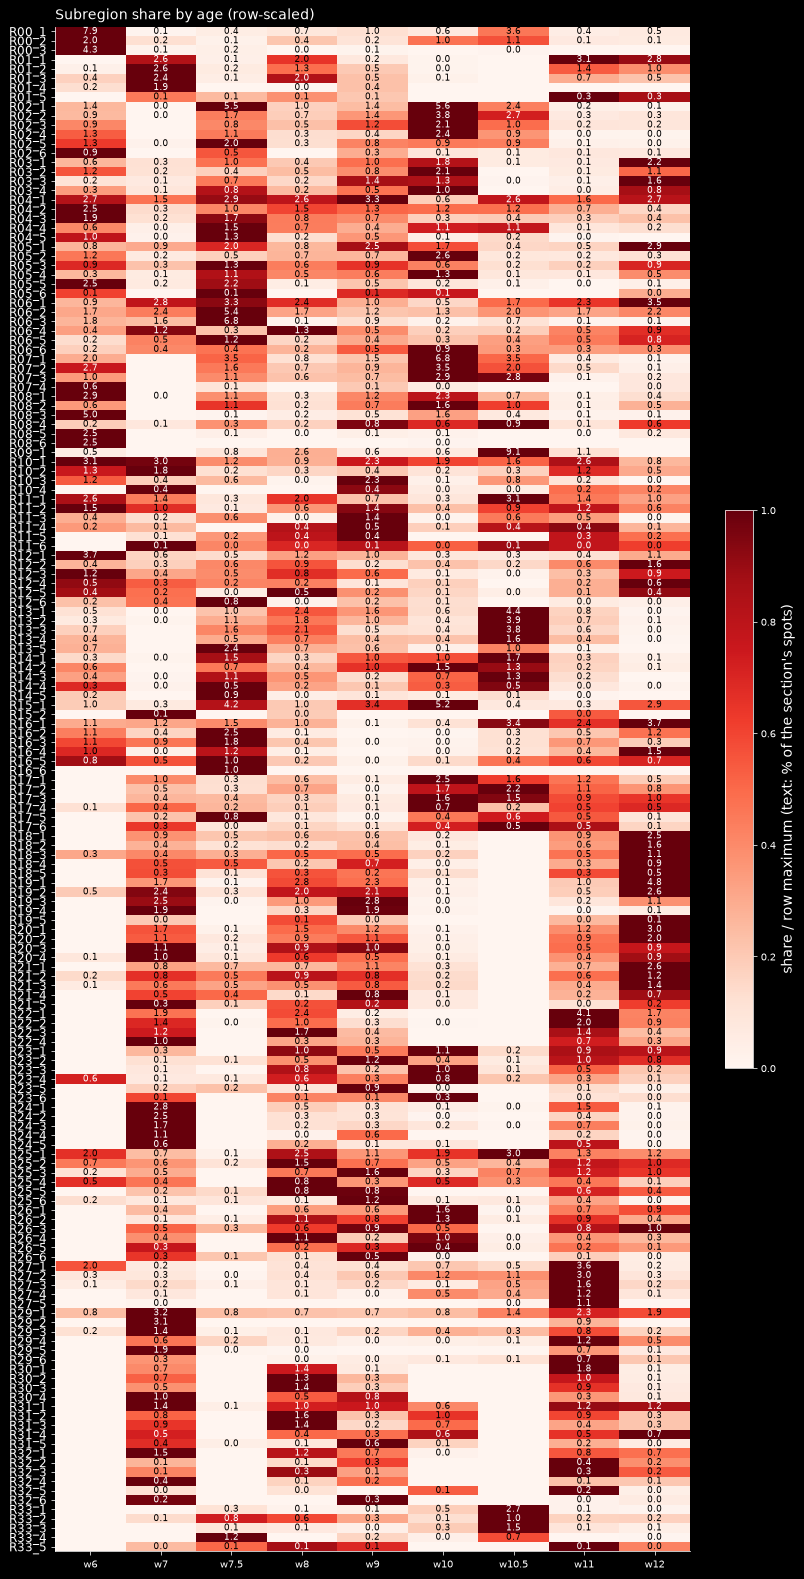

In [24]:
force=False
verbose=False

adata_vis.obs['sub_region_id'] = adata_expr.obs['sub_region_id'].reindex(adata_vis.obs_names).astype(str)

df_sub_age = sch.calc_df_region_age(adata_vis[adata_vis.obs['sub_region_id'] != 'nan'], key='sub_region_id',
                                    fname=sch.fname('tsv_subregion_age'), force=force, verbose=verbose)

fig = sch.plot_group_age_heatmap(df_sub_age, group_col='region', figsize=(10, 22), title='Subregion share by age (row-scaled)',
                                 fname=sch.fname('fig_subregion_age'), force=force, verbose=verbose)
plt.show()

### 9. Subregion signatures on the scRNA reference

Which reference cell types express each subregion's signature? **sch.calc_df_subregion_ref_score**: for every **supported** subregion, the top 25 subregion-signature genes found in the reference (>= 3 genes); cell score = mean per-gene z-score of log1p(CP10k); mean per cell type. Rare types with very specific genes reach high scores; compare cell types **within a row**.

In [25]:
force=False
verbose=False

adata_ref = sch.filter_reference(sch.read_h5ad('reference', set_self=False))
adata_ref_sym = adata_ref.copy()
adata_ref_sym.var_names = adata_ref_sym.var['symbol'].astype(str).values
adata_ref_sym.var_names_make_unique()

df_ref_score, df_cell_score, genes_used = sch.calc_df_subregion_ref_score(adata_ref_sym, df_gene_sets, df_sub_table,
                                                                          force=force, verbose=verbose)
ref_top = sch.calc_df_ref_top(df_ref_score, n=3)
print(df_ref_score.shape, "(subregions x cell types)")

ref_top.to_frame()

(123, 31) (subregions x cell types)


,ref_cell_types
R00_2,"EPDC (0.34), Int_FB (0.33), Prol_FB (0.28)"
R00_3,"MyC (0.31), PDE4Chigh_EC (0.21), PDE4Chigh_FB (0.13)"
R01_2,"EPDC (0.89), Int_FB (0.80), Peric_MC (0.78)"
R01_3,"Endoc_EC (1.58), EndocCush_EC (0.98), PDE4Chigh_EC (0.41)"
R01_4,"MyC (0.25), PDE4Chigh_EC (0.14), LyC (0.14)"
R01_5,"PDE4Chigh_EC (0.25), MetAct_vCM_2 (0.16), LEC (0.14)"
R02_1,"Mat_aCM (0.52), LEC (0.33), Mat_vCM (0.18)"
R02_2,"MicroVasc_EC (0.72), PDE4Chigh_EC (0.60), MacroVasc_EC (0.59)"
R02_3,"Mat_aCM (0.39), OFT_SMC (0.15), Endoc_EC (0.14)"
R02_4,"Endoc_EC (1.24), EndocCush_EC (0.70), PDE4Chigh_EC (0.13)"


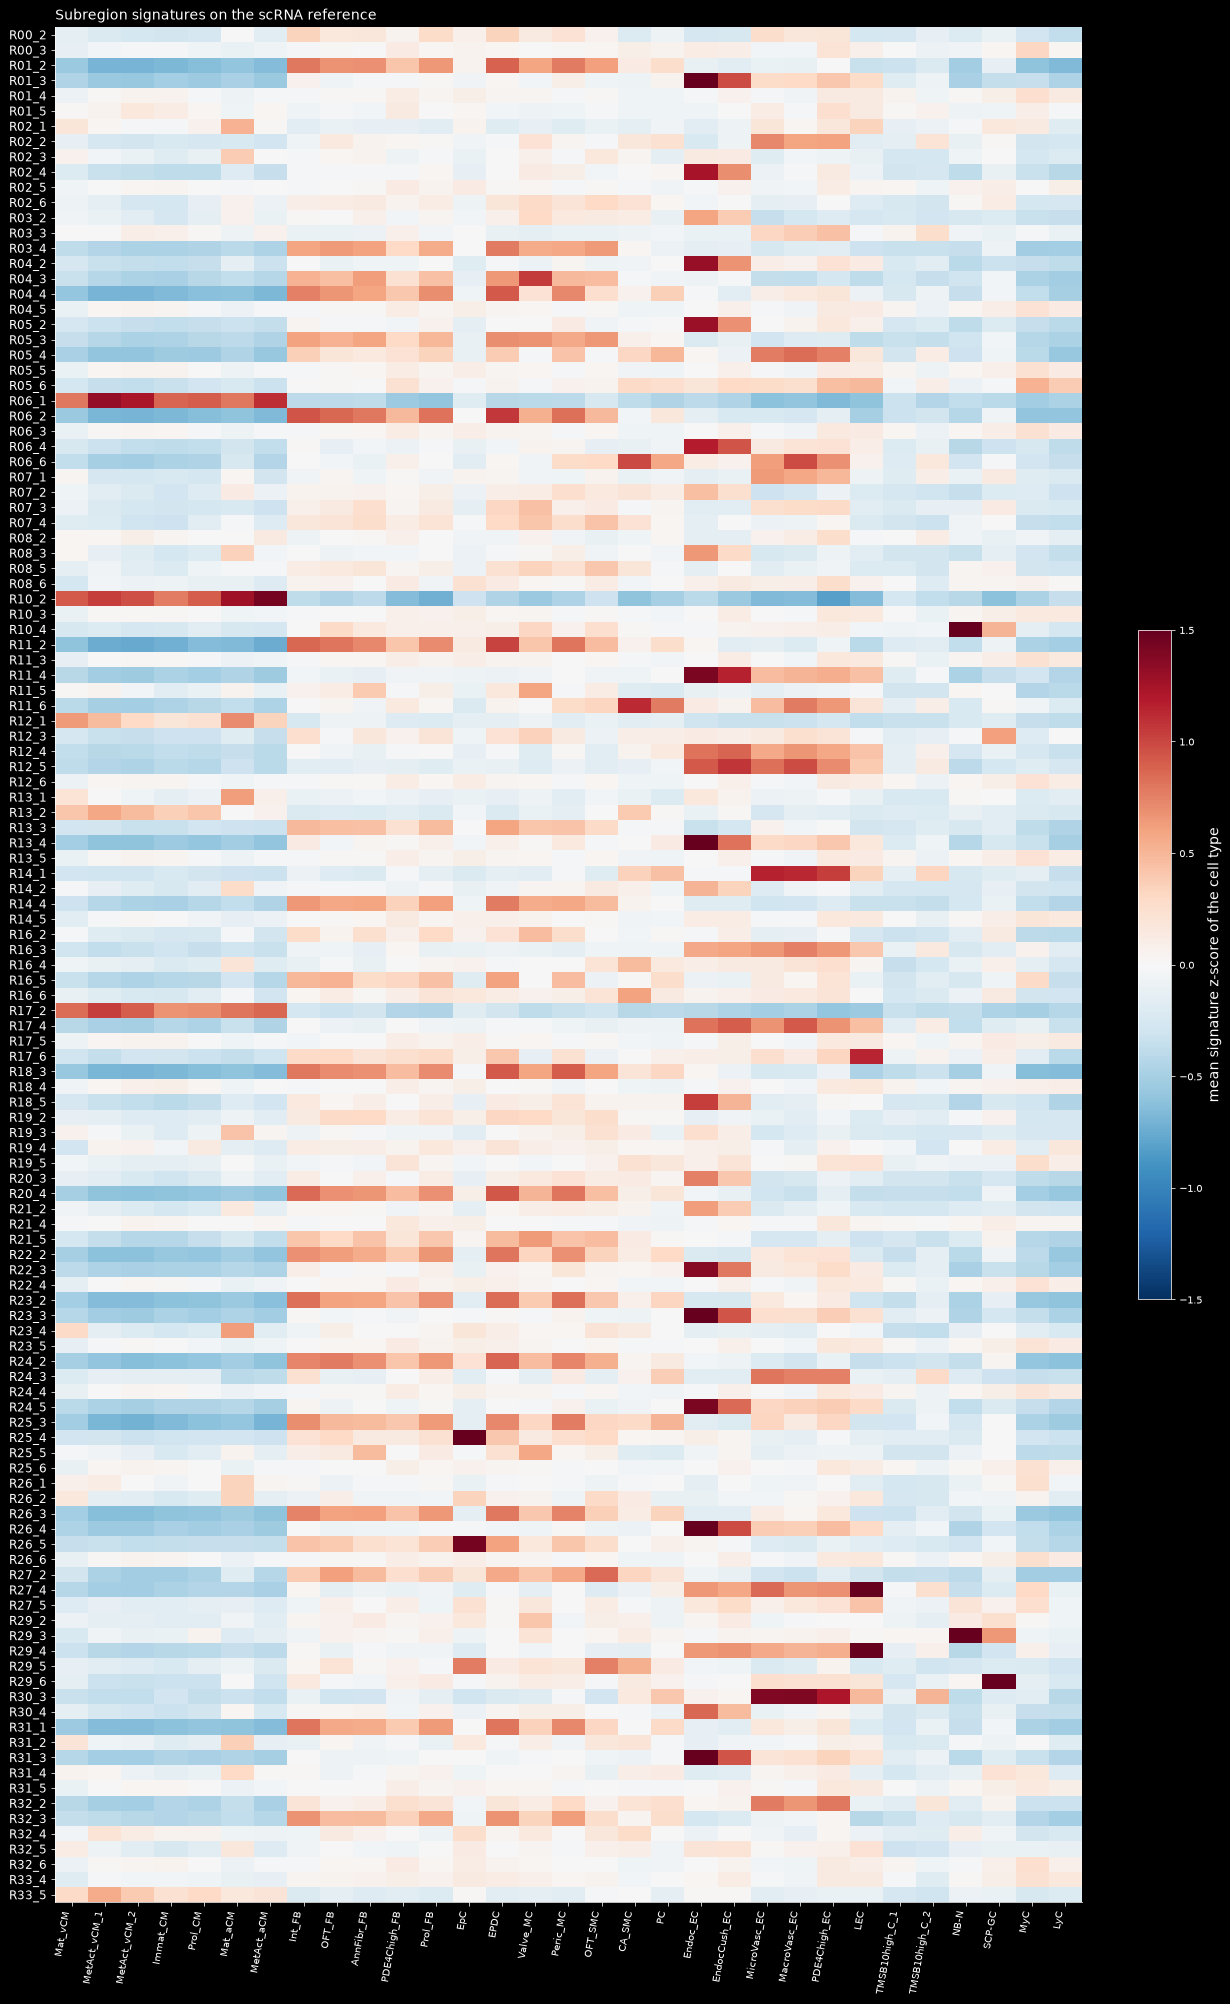

In [26]:
force=False
verbose=False

fig = sch.plot_subregion_ref_heatmap(df_ref_score, figsize=(16, max(6, 0.22 * len(df_ref_score))), fname=sch.fname('fig_ref_heatmap'),
                                     force=force, verbose=verbose)
plt.show()

### 10. Tables

**Table region**

In [27]:
force=False
verbose=False

df_region_table = sch.update_region_table_subregions(df_region_table, adata_expr, force=force, verbose=verbose)
df_region_table

,region_id,region_name,signature_genes,functional_description,compartment,n_spots,median_UMIs,median_cells_per_spot,n_subregions,n_signature_genes,enriched_cell_types
0,R00,Trabecular ventricular myocardium and endocardium,"TGM2, MB, IRX3, CRNDE, ATP1B1, ATP1A1, MYOM2, BMP10, COL18A1, P2RX1, IRX5, MASP1","Endoc_EC 3.8x and EndocCush_EC 2.7x in ventricular CM: trabeculae lined by endocardium (paper EN 32%, LV_T 22%, VCS ...",ventricle / endocardium,953,7114,62,3,128,"Endoc_EC (x3.8), EndocCush_EC (x2.6), Mat_vCM (x1.8)"
1,R01,"Ventricular myocardium at the lumen, MetAct_vCM_2 (low genes)","MYL2, FABP3, FHL2, CRYAB, MYH7, COX6A2, MYL3, ACTA1","MetAct_vCM_2 1.6x and TMSB10high_C_1 1.8x, few genes per spot; borders the ventricular lumen (paper EN 21%, B_V 18%)...",ventricle,2333,2040,47,5,8,"TMSB10high_C_1 (x1.8), MetAct_vCM_2 (x1.6), EndocCush_EC (x1.6)"
2,R02,"Compact ventricular myocardium, depth tier 3","NREP, SORBS2, SLC8A1, TNNC1, GJA1, MYL3, RBM24, TNNI3, RHOQ, NAV1, VEGFA, SMYD1","Mat_vCM 38%, PDE4Chigh_EC 2.5x: compact wall of both ventricles (paper LV_C 34%, RV_C 25%); stereoscope R03 / R02 / ...",ventricle,3089,6679,69,6,159,"PDE4Chigh_EC (x2.5), Mat_vCM (x2.4), Prol_FB (x2.1)"
3,R03,"Compact ventricular myocardium, depth tier 4, RV-rich","MYL3, TPM1, TNNI1, MYH7, COX6C, SLC25A4, COX6A2, RRAD, MYL2, CRYAB, PLN, MDH1","MetAct_vCM_1 33%, Mat_vCM 29%, PDE4Chigh_EC 2.3x; mostly w10-w12 (72%) (paper RV_C 33%, LV_C 22%). Median 85.3 cells...",ventricle,1866,7118,85,4,119,"PDE4Chigh_EC (x2.3), MetAct_vCM_1 (x2.3), Mat_vCM (x2.2)"
4,R04,"Ventricular myocardium near endocardium and AV plane, low depth","MYH7, MYL2, MYL3, IRX3","Mat_vCM 40% with endocardial and cushion EC (1.6-1.7x) and CA_SMC 1.5x (paper EN 19%, AVP_V 14%). Median 34.6 cells/...",ventricle / AV plane,3030,3392,35,5,5,"Prol_FB (x1.7), Endoc_EC (x1.6), EndocCush_EC (x1.6)"
5,R05,"Ventricular myocardium near endocardium, depth tier 2","MYH7, MYL2, FHL2, MYL3, LBH, MT3, IRX4","Mat_vCM 33%, Endoc_EC 1.7x (paper EN 19%, LV_C 15%, SCV 14%). Median 51.3 cells/spot (q05), 6,784 UMIs.",ventricle,2344,4783,51,6,7,"Endoc_EC (x1.7), Mat_vCM (x1.5), PDE4Chigh_EC (x1.4)"
6,R06,"Subepicardial and perivascular tissue, mixed, low depth","MYL2, MYH7, HBZ","CA_SMC 3.5x, EPDC 2.5x, MacroVasc_EC 2.0x, AnnFibr_FB 1.8x in CM background; spread over all 38 sections; no single ...",epicardium / vessels,4269,2426,24,6,3,"CA_SMC (x3.4), EPDC (x2.5), MacroVasc_EC (x2.0)"
7,R07,"Compact ventricular myocardium, depth tier 4, LV-rich","NREP, GJA1, SLC25A3, SLC8A1, SORBS2, TNNC1, TNNI3, NAV1, MYOM1, MYL3, VEGFA, HSPB7","Mat_vCM 39%, PDE4Chigh_EC 3.1x, PDE4Chigh_FB 2.6x (paper LV_C 47%, RV_C 22%); stereoscope R07 / R03. Median 85.4 cel...",ventricle,2629,8255,85,4,333,"PDE4Chigh_EC (x3.2), Mat_vCM (x3.1), Int_FB (x2.5)"
8,R08,"Compact ventricular myocardium, depth tier 5","ATP5F1B, RBM24, MDH1, HEY2, GJA1, PPP1R3C, SLC25A3, MYL3, VEGFA, NREP, TNNC1, BNIP3","Mat_vCM 33%, PDE4Chigh_EC 3.6x, PDE4Chigh_FB 3.2x (paper LV_C 46%); deepest ventricular spots. Median 110.1 cells/sp...",ventricle,1574,11008,110,6,521,"PDE4Chigh_EC (x3.6), Mat_vCM (x3.5), Prol_CM (x3.2)"
9,R09,"Ventricular myocardium, Mat_vCM-rich, w8 onwards","HSPB7, MYBPC3, PPP1R12B, MYOM1, SLC8A1, LDB3, NREP, NAV1, TNNI3, TTN, PYGB, POPDC2","Mat_vCM 48% (2.6x); 19 sections, 31% from V11A20-401_C1; w6-w7 3% (paper LV_C 36%, RV_T 26%). Median 62.1 cells/spot...",ventricle,1093,6162,62,1,257,"Mat_vCM (x2.7), Prol_FB (x2.5), PDE4Chigh_EC (x2.2)"


**Table subregion** (with the reference cell types of section 9; '' = not scored)

In [28]:
force=False
verbose=False

df_sub_table = sch.add_ref_cell_types(df_sub_table, df_ref_score, n=3, force=force, verbose=verbose)

cols = ['region_id', 'sub_region_id', 'status', 'subregion_signature_genes', 'not_present_genes',
        'enriched_cell_types', 'ref_cell_types', 'functional_description']

df_sub_table[cols]

,region_id,sub_region_id,status,subregion_signature_genes,not_present_genes,enriched_cell_types,ref_cell_types,functional_description
0,R00,R00_1,weak; single-section,"FBN2, ACTA2, ALDOC, VCAN, LGALS3, NMRK2, LRIG1, S100A4, SPEG, CLU, HES1, IRX1",,"Endoc_EC (x1.4), EndocCush_EC (x1.3), Mat_vCM (x1.3)",,"Part of R00; enriched for Endoc_EC (x1.4), EndocCush_EC (x1.3), Mat_vCM (x1.3); markers FBN2, ACTA2, ALDOC, VCAN, LG..."
1,R00,R00_2,supported; single-section,"H19, PAM, MYH6, DCN, KRT8, SSR3, COL1A1, KRT18, DLK1, OGN, BVES, TNFRSF19",IRX1,"EPDC (x4.6), EpC (x4.2), AnnFibr_FB (x3.4)","EPDC (0.34), Int_FB (0.33), Prol_FB (0.28)","Part of R00; enriched for EPDC (x4.6), EpC (x4.2), AnnFibr_FB (x3.4); markers H19, PAM, MYH6, DCN, KRT8; lacks IRX1."
2,R00,R00_3,supported; single-section; high-depth,"HBA1, SLC25A37, HBA2, FTL, HBG1, AHSP, BLVRB, SLC4A1, TENT5C, MT1G, ALAS2, GYPB",,"EndocCush_EC (x3.9), MyC (x3.4), Endoc_EC (x3.3)","MyC (0.31), PDE4Chigh_EC (0.21), PDE4Chigh_FB (0.13)","Part of R00; enriched for EndocCush_EC (x3.9), MyC (x3.4), Endoc_EC (x3.3); markers HBA1, SLC25A37, HBA2, FTL, HBG1."
3,R01,R01_1,weak; single-section,"MT3, RBP7",FMOD,"Mat_vCM (x1.1), MetAct_vCM_1 (x1.1), Prol_CM (x1.0)",,"Part of R01; enriched for Mat_vCM (x1.1), MetAct_vCM_1 (x1.1), Prol_CM (x1.0); markers MT3, RBP7; lacks FMOD."
4,R01,R01_2,supported; single-section,"COL1A1, COL1A2, SPARC, H19, DCN, PTN, FBLN1, LGALS1, TAGLN, COL6A2, COL3A1, MGP",,"EPDC (x6.6), CA_SMC (x6.1), Valve_MC (x5.8)","EPDC (0.89), Int_FB (0.80), Peric_MC (0.78)","Part of R01; enriched for EPDC (x6.6), CA_SMC (x6.1), Valve_MC (x5.8); markers COL1A1, COL1A2, SPARC, H19, DCN."
5,R01,R01_3,supported; single-section; high-depth,"POSTN, FN1, CDH11, ENG, COLEC11, CTHRC1, COL3A1, LEPR, ECSCR, EMCN, TFPI, SAT1",,"Endoc_EC (x13.6), EndocCush_EC (x6.3), Mat_aCM (x2.0)","Endoc_EC (1.58), EndocCush_EC (0.98), PDE4Chigh_EC (0.41)","Part of R01; enriched for Endoc_EC (x13.6), EndocCush_EC (x6.3), Mat_aCM (x2.0); markers POSTN, FN1, CDH11, ENG, COL..."
6,R01,R01_4,supported; single-section; high-depth,"HBA1, HBA2, HBG1, SLC25A37, HBZ, AHSP, HBE1, FTL, HEMGN, HBB, SLC4A1, ALAS2",,"LyC (x5.2), EndocCush_EC (x3.7), NB-N (x3.6)","MyC (0.25), PDE4Chigh_EC (0.14), LyC (0.14)","Part of R01; enriched for LyC (x5.2), EndocCush_EC (x3.7), NB-N (x3.6); markers HBA1, HBA2, HBG1, SLC25A37, HBZ."
7,R01,R01_5,supported; single-section,"HBA1, HBG1, HBA2, HBB, ALAS2, HBM, SLC25A37, GYPC, HEMGN",,"OFT_SMC (x1.4), PDE4Chigh_EC (x1.3), MetAct_vCM_2 (x1.1)","PDE4Chigh_EC (0.25), MetAct_vCM_2 (0.16), LEC (0.14)","Part of R01; enriched for OFT_SMC (x1.4), PDE4Chigh_EC (x1.3), MetAct_vCM_2 (x1.1); markers HBA1, HBG1, HBA2, HBB, A..."
8,R02,R02_1,supported; single-section,"FREM2, CD36, TRH, COL2A1, RNF175, CLDN6",,"MicroVasc_EC (x1.5), PC (x1.4), MyC (x1.4)","Mat_aCM (0.52), LEC (0.33), Mat_vCM (0.18)","Part of R02; enriched for MicroVasc_EC (x1.5), PC (x1.4), MyC (x1.4); markers FREM2, CD36, TRH, COL2A1, RNF175."
9,R02,R02_2,supported; single-section,"PRDM8, FABP4, TNFRSF19, PRRX1, TNNT3, TCIM, COL11A2, APLNR, CPE",,"PDE4Chigh_EC (x1.5), MacroVasc_EC (x1.4), MicroVasc_EC (x1.4)","MicroVasc_EC (0.72), PDE4Chigh_EC (0.60), MacroVasc_EC (0.59)","Part of R02; enriched for PDE4Chigh_EC (x1.5), MacroVasc_EC (x1.4), MicroVasc_EC (x1.4); markers PRDM8, FABP4, TNFRS..."


### Notes for interpretation

- **supported** = spatially coherent (ratio >= 1.5) with >= 3 own signature genes; **weak** subregions are not distinct from the rest of their region.

- **Laterality and layers.** Ventricular regions (compact, trabecular) are compositionally alike in LV and RV, so their subregions often split **left vs right** (*HAND1*, *TBX5* vs *HAND2*, *IRX* genes) or **compact vs trabecular** (*HEY2* vs *NPPA*, *IRX3*): the expression differences the abundance clustering could not see. Compare with the paper's clusters (LV_C, RV_C, LV_T, RV_T; mp_heart_dvlp02).
- **Blood subregions.** Subregions whose signature is haemoglobin genes (*HBA1/2*, *HBG1/2*, *HBB*, *ALAS2*, *AHSP*, *SLC4A1*; e.g. R01_2, R03_5, R07_5) are blood in the chamber and vessel lumens (the paper's clusters **B_A** / **B_V**, blood in atria / ventricles). The authors removed the red-blood-cell clusters (HL_excl_*) from the reference, so these spots have no matching cell type: their abundances are spread over the remaining types, and their reference scores (section 9) are low and unspecific. They can be excluded from the LR analysis of mp_heart_dvlp04 by their status or signature.
- **Other recurring structures.** Macrophage (*C1QA*, *CSF1R*, *LYVE1*), platelet (*PF4*, *PPBP*, *ITGA2B*), vascular (*CD93*, *ESAM*, *PDGFB*) and fibroblast / valve (*POSTN*, *PRRX1*, *COL1A1*) subregions appear inside several myocardial regions: tissue elements that the abundance regions merged into the myocardium.
- **Developmental stage.** Section 8 separates subregions shared by all ages from stage-specific ones; with 1-3 hearts per age, a stage-specific subregion should be checked heart by heart.
- **Parameters.** Subregion IDs and gene sets depend on the parameters and on the regions (abundance source); after a change, rerun with **force=False** and recheck the descriptions.